# Part 2 — Furniture Target Achievement Analysis

## Objective

Analyze monthly target sales for the **Furniture** category, calculate month-over-month target changes, compare targets with actual Furniture sales, identify significant target fluctuations, and suggest strategies for better target alignment.

### Assignment requirement

> Using the Sales Target dataset, calculate the percentage change in target sales for the Furniture category month-over-month, analyse significant fluctuations, and suggest strategies for aligning target expectations with actual performance trends.


## 1. Data Sources

### Sales Target Dataset

The original Sales Target PDF contains monthly targets for Furniture, Clothing, and Electronics.

### Actual Sales Dataset

Actual Furniture sales are derived from the processed order dataset created in **Part 1**.

We reuse the processed dataset rather than duplicating the original order PDFs.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd().parent

TARGET_PATH = BASE_DIR / "data/processed/sales_target_clean.csv"
SALES_PATH = (
    BASE_DIR
    / "../Part_1_Sales_Profitability/data/processed/merged_order_data.csv"
)

target_df = pd.read_csv(TARGET_PATH)
sales_df = pd.read_csv(SALES_PATH)

print("Target data shape:", target_df.shape)
print("Sales data shape:", sales_df.shape)


Target data shape: (36, 3)
Sales data shape: (1500, 10)


## 2. Validate the Target Dataset

The cleaned target dataset should contain:

- 36 records
- 12 months for each of 3 categories
- Furniture records covering April 2018 to March 2019


In [2]:
print(target_df.head())

print("\nMissing values:")
print(target_df.isnull().sum())

print("\nCategory counts:")
print(target_df["Category"].value_counts())


    Month   Category  Target
0  Apr-18  Furniture   10400
1  May-18  Furniture   10500
2  Jun-18  Furniture   10600
3  Jul-18  Furniture   10800
4  Aug-18  Furniture   10900

Missing values:
Month       0
Category    0
Target      0
dtype: int64

Category counts:
Category
Furniture      12
Clothing       12
Electronics    12
Name: count, dtype: int64


## 3. Furniture Target Analysis

We filter the target dataset to Furniture and calculate the month-over-month percentage change:

$$
MoM\ Change\ \% =
\frac{Current\ Target - Previous\ Target}
{Previous\ Target}
\times 100
$$

April 2018 is treated as the baseline, so it has no previous month and therefore no MoM percentage.


In [3]:
furniture_targets = target_df[
    target_df["Category"] == "Furniture"
].copy()

furniture_targets["Month"] = pd.to_datetime(
    furniture_targets["Month"],
    format="%b-%y"
)

furniture_targets = furniture_targets.sort_values("Month")

furniture_targets["MoM_Target_Change_%"] = (
    furniture_targets["Target"].pct_change() * 100
)

furniture_targets[["Month", "Target", "MoM_Target_Change_%"]]


,Month,Target,MoM_Target_Change_%
0,2018-04-01,10400,NaN
1,2018-05-01,10500,0.961538
2,2018-06-01,10600,0.952381
3,2018-07-01,10800,1.886792
4,2018-08-01,10900,0.925926
5,2018-09-01,11000,0.917431
6,2018-10-01,11100,0.909091
7,2018-11-01,11300,1.801802
8,2018-12-01,11400,0.884956
9,2019-01-01,11500,0.877193


## 4. Identify Significant Target Fluctuations

For this analysis, an absolute month-over-month target change greater than 1.5% is used as an analytical threshold to highlight relatively large target changes within this dataset.

This threshold is a convention for analysis and is **not provided by the source dataset**.


In [4]:
furniture_targets["Significant_Target_Fluctuation"] = (
    furniture_targets["MoM_Target_Change_%"].abs() > 1.5
)

furniture_targets[
    furniture_targets["Significant_Target_Fluctuation"]
][["Month", "Target", "MoM_Target_Change_%"]]


,Month,Target,MoM_Target_Change_%
3,2018-07-01,10800,1.886792
7,2018-11-01,11300,1.801802
11,2019-03-01,11800,1.724138


### Finding

The larger target increases occur in:

- **July 2018:** +1.89%
- **November 2018:** +1.80%
- **March 2019:** +1.72%

The target increases every month; there are no month-over-month decreases in the Furniture target.


## 5. Calculate Actual Monthly Furniture Sales

Actual sales are calculated from the Part 1 processed order dataset.

The `Amount` field is aggregated by month after filtering for the Furniture category.


In [5]:
sales_df["Order Date"] = pd.to_datetime(sales_df["Order Date"])

furniture_sales = sales_df[
    sales_df["Category"] == "Furniture"
].copy()

monthly_sales = (
    furniture_sales
    .groupby(furniture_sales["Order Date"].dt.to_period("M"))["Amount"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Actual_Sales"]
monthly_sales["Month"] = monthly_sales["Month"].dt.to_timestamp()

monthly_sales


,Month,Actual_Sales
0,2018-04-01,8121
1,2018-05-01,6220
2,2018-06-01,5532
3,2018-07-01,3483
4,2018-08-01,9538
5,2018-09-01,8704
6,2018-10-01,6766
7,2018-11-01,15165
8,2018-12-01,9474
9,2019-01-01,21257


## 6. Compare Target with Actual Sales

We calculate:

### Target Achievement

$$
Achievement\ \% =
\frac{Actual\ Sales}{Target\ Sales}
\times 100
$$

### Sales Gap

$$
Gap = Actual\ Sales - Target\ Sales
$$


In [6]:
comparison = furniture_targets.merge(
    monthly_sales,
    on="Month",
    how="left"
)

comparison["Achievement_%"] = (
    comparison["Actual_Sales"]
    / comparison["Target"]
    * 100
)

comparison["Gap"] = (
    comparison["Actual_Sales"]
    - comparison["Target"]
)

comparison["Achievement_Deviation_%"] = (
    comparison["Achievement_%"] - 100
)

comparison[[
    "Month",
    "Target",
    "Actual_Sales",
    "MoM_Target_Change_%",
    "Achievement_%",
    "Gap"
]]


,Month,Target,Actual_Sales,MoM_Target_Change_%,Achievement_%,Gap
0,2018-04-01,10400,8121,NaN,78.086538,-2279
1,2018-05-01,10500,6220,0.961538,59.238095,-4280
2,2018-06-01,10600,5532,0.952381,52.188679,-5068
3,2018-07-01,10800,3483,1.886792,32.250000,-7317
4,2018-08-01,10900,9538,0.925926,87.504587,-1362
5,2018-09-01,11000,8704,0.917431,79.127273,-2296
6,2018-10-01,11100,6766,0.909091,60.954955,-4334
7,2018-11-01,11300,15165,1.801802,134.203540,3865
8,2018-12-01,11400,9474,0.884956,83.105263,-1926
9,2019-01-01,11500,21257,0.877193,184.843478,9757


## 7. Target vs Actual Visualization

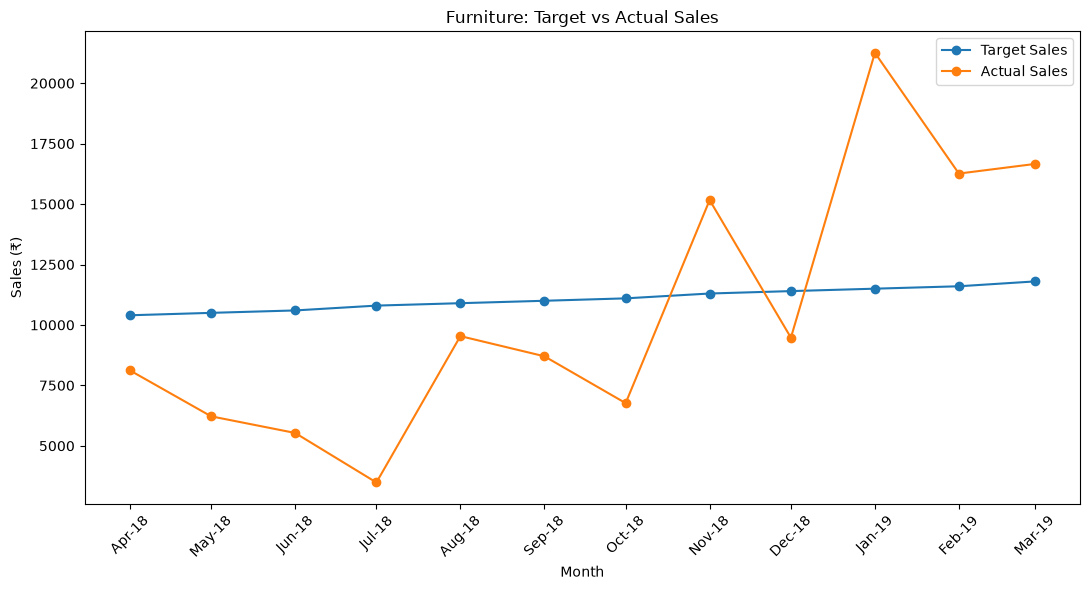

In [7]:
plt.figure(figsize=(11, 6))

plt.plot(
    comparison["Month"],
    comparison["Target"],
    marker="o",
    label="Target Sales"
)

plt.plot(
    comparison["Month"],
    comparison["Actual_Sales"],
    marker="o",
    label="Actual Sales"
)

plt.title("Furniture: Target vs Actual Sales")
plt.xlabel("Month")
plt.ylabel("Sales (₹)")
plt.xticks(
    comparison["Month"],
    comparison["Month"].dt.strftime("%b-%y"),
    rotation=45
)
plt.legend()
plt.tight_layout()
plt.show()


## 8. Target Achievement Visualization

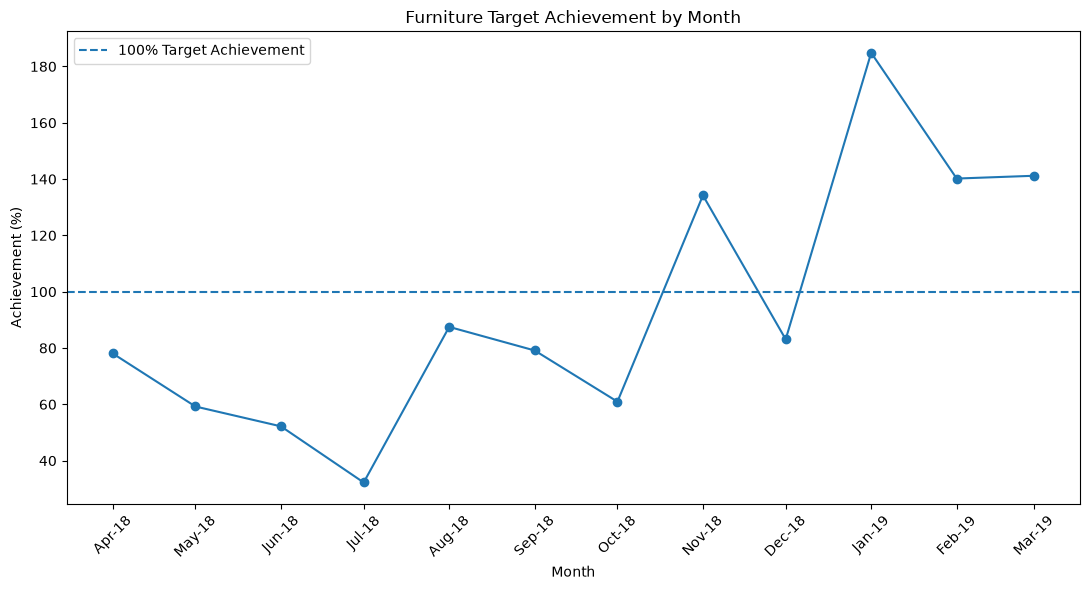

In [8]:
plt.figure(figsize=(11, 6))

plt.plot(
    comparison["Month"],
    comparison["Achievement_%"],
    marker="o"
)

plt.axhline(
    100,
    linestyle="--",
    label="100% Target Achievement"
)

plt.title("Furniture Target Achievement by Month")
plt.xlabel("Month")
plt.ylabel("Achievement (%)")
plt.xticks(
    comparison["Month"],
    comparison["Month"].dt.strftime("%b-%y"),
    rotation=45
)
plt.legend()
plt.tight_layout()
plt.show()


## 9. Month-over-Month Target Change Visualization

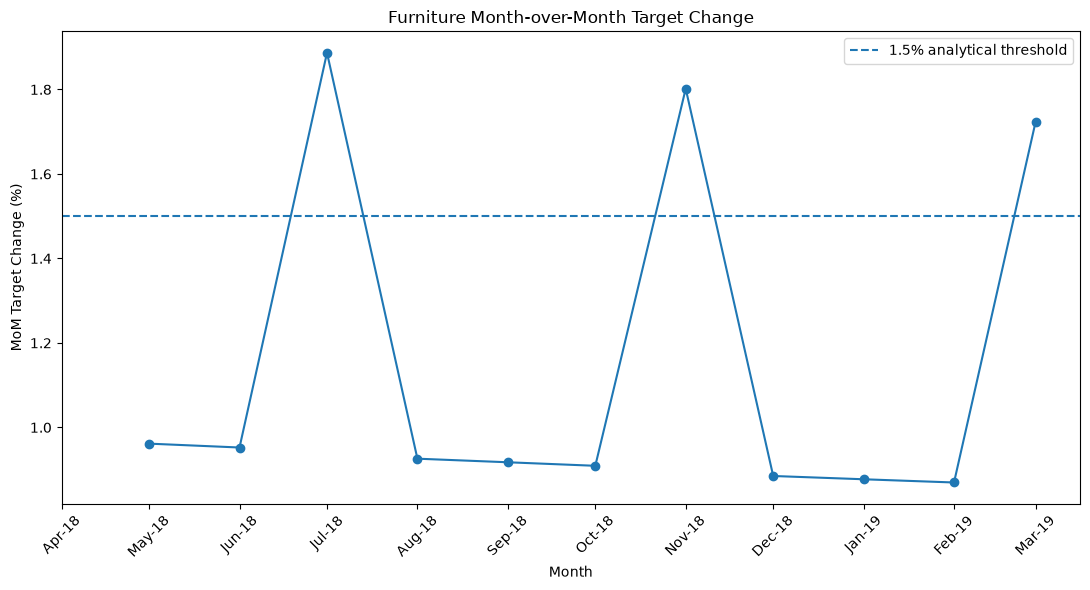

In [9]:
plt.figure(figsize=(11, 6))

plt.plot(
    comparison["Month"],
    comparison["MoM_Target_Change_%"],
    marker="o"
)

plt.axhline(
    1.5,
    linestyle="--",
    label="1.5% analytical threshold"
)

plt.title("Furniture Month-over-Month Target Change")
plt.xlabel("Month")
plt.ylabel("MoM Target Change (%)")
plt.xticks(
    comparison["Month"],
    comparison["Month"].dt.strftime("%b-%y"),
    rotation=45
)
plt.legend()
plt.tight_layout()
plt.show()


## 10. Key Findings

### Target trend

Furniture targets increase steadily from **₹10,400 in April 2018** to **₹11,800 in March 2019**.

The largest month-over-month target increases are:

- **July 2018:** +1.89%
- **November 2018:** +1.80%
- **March 2019:** +1.72%

### Actual performance

Actual Furniture sales are substantially more variable than the target trajectory.

The lowest monthly actual sales occur in **July 2018 (₹3,483)**, while the highest occur in **January 2019 (₹21,257)**.

### Target alignment

The weakest target achievement occurs in **July 2018 at 32.2%**.

Performance exceeds target in:

- **November 2018:** 134.2%
- **January 2019:** 184.8%
- **February 2019:** 140.2%
- **March 2019:** 141.2%

This indicates a mismatch between the relatively smooth target trajectory and the much greater variability in actual sales.


## 11. Strategies for Aligning Targets with Actual Performance

### 1. Use rolling actual performance

Use recent 2–3 month Furniture sales as an input when setting the next month's target instead of relying only on a fixed upward progression.

### 2. Introduce base and stretch targets

A base target can reflect expected performance while a stretch target can reflect stronger demand scenarios. This provides flexibility when demand is volatile.

### 3. Review large performance deviations

Months with very low or very high achievement should trigger a review of factors such as product mix, promotions, inventory availability, pricing, and demand patterns.

These factors are potential areas for investigation; the current dataset alone does not establish causality.

### 4. Add a target revision mechanism

If actual performance remains materially above or below target for consecutive months, future targets should be recalibrated rather than continuing the same trajectory.

### 5. Use more granular targets

Furniture contains multiple subcategories with different sales and profitability characteristics. Subcategory-level targets could provide a more precise view of expected performance.


## 12. Conclusion

The Furniture target increased consistently throughout the period, but actual sales were significantly more volatile.

The analysis suggests that target setting could be improved by incorporating recent actual performance, demand variability, and more granular category information.

The goal should not simply be to increase targets each month, but to set targets that are ambitious while remaining grounded in observed business performance.
